# Calendar-Aware Daily Demand Forecasting: A Comparative Study of LightGBM and LSTM (v4: training time)

**Dataset:** M5 Forecasting – Accuracy (Walmart) · **Scope:** one store (CA_1) × one category (FOODS), stratified sample of items
**Main task:** 1-day-ahead demand forecasting for each item, using demand history + calendar/date-type + price information.

### Experimental protocol (read this first)
| Element | Choice |
|---|---|
| Horizon | **1 day ahead** for the main experiment |
| Split | Chronological 70 / 15 / 15 (train / validation / test), no shuffling |
| Models | Naive, Seasonal Naive (lag 7), MA28 · LightGBM · LSTM (two-branch, uses *future-known* calendar of the forecast day) |
| Ablation | **A** = demand history only · **B** = A + calendar & date type · **C** = B + price & SNAP |
| Fairness | Same table, same split, same evaluation rows `(item_id, date)` for every model; same item information (LightGBM `item_cat`, LSTM item embedding) |
| Metrics | MAE, RMSE, **WAPE**, **RMSSE**, **Bias** (+ sMAPE as auxiliary only) · error by date type · **training time** (wall-clock, same hardware) |


## 0. Setup and configuration

In [1]:
import os, gc, random, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

# --- TẢI DỮ LIỆU TRỰC TIẾP TỪ KAGGLE MỚI ---
try:
    import kagglehub
    print("Đang tải dữ liệu M5 từ Kaggle (aryayadav0513)...")
    # Tải dataset m5-forecasting-accuracy từ link mới bạn cung cấp
    KAGGLE_PATH = kagglehub.dataset_download("aryayadav0513/m5-forecasting-accuracy")
    DATA_DIR = KAGGLE_PATH
    print(f"Dữ liệu đã được tải về thành công tại: {DATA_DIR}")
except Exception as e:
    print(f"Lỗi khi tải từ Kaggle: {e}. Chuyển sang sử dụng thư mục tạm cục bộ.")
    DATA_DIR = "/content/M5_Data"

OUT_DIR   = os.path.join(DATA_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

STORE_ID  = "CA_1"
CAT_ID    = "FOODS"
N_ITEMS   = 100            # items sampled (stratified by sales volume); 100-200 runs fine on Colab
N_BINS    = 5              # number of volume strata
SEED      = 42

LOOKBACK  = 28             # LSTM input window (days)
HORIZON   = 1              # 1-day-ahead forecasting (do NOT change)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

# LSTM training
SEEDS       = [42, 7, 2024]
# several seeds -> report mean ± std (DL is stochastic)
EPOCHS      = 40
BATCH_SIZE  = 256
PATIENCE    = 6
LSTM_UNITS  = (64, 32)
DROPOUT     = 0.2
LSTM_LOSS   = "poisson"        # "poisson" (count data, pairs with softplus output) | "mse" | "huber"

# ------------------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)
STATE = STORE_ID.split("_")[0]
assert HORIZON == 1, "This notebook evaluates 1-day-ahead forecasts only."

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

# ---- training-time helpers (verbatim copy of src/m5cal/timing.py) ----
from typing import Mapping, Sequence


class StopWatch:
    """Đồng hồ bấm giờ dùng với `with`: `with StopWatch() as sw: ...; sw.seconds`."""

    def __enter__(self):
        self._t0 = time.perf_counter()
        self.seconds = float("nan")
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self._t0
        return False


def hardware_info(gpu_devices: Sequence | None = None) -> dict:
    """Mô tả phần cứng để ghi kèm số đo thời gian (thời gian chỉ so được trên cùng phần cứng)."""
    return {"python": platform.python_version(), "machine": platform.machine(),
            "processor": platform.processor() or "n/a", "cpu_count": os.cpu_count(),
            "gpu": ", ".join(str(d) for d in gpu_devices) if gpu_devices else "none (CPU only)"}


def summarise_training_time(lgb_log: pd.DataFrame, lstm_log: pd.DataFrame,
                            results: pd.DataFrame | None = None) -> pd.DataFrame:
    """Gộp nhật ký thời gian thành một bảng theo mô hình × bộ biến.

    lgb_log  : một dòng cho mỗi lần huấn luyện LightGBM, cột `set`, `fit_sec`, `best_iter`, `selected` (bool).
    lstm_log : một dòng cho mỗi lần huấn luyện LSTM (mỗi seed), cột `set`, `sec`, `epochs`.
    results  : bảng chỉ số trên tập test, index là tên mô hình ("LightGBM-A", "LSTM-B", ...).

    Trả về các cột: model, set, fits, total_train_sec (tổng mọi lần huấn luyện của bộ đó: 3 cấu hình
    với LightGBM, 3 seed với LSTM), sec_per_fit, final_model_sec (thời gian của mô hình dùng để dự báo:
    cấu hình được chọn với LightGBM, trung bình một seed với LSTM), units (số cây / số epoch trung bình)
    và các chỉ số WAPE_%, MAE, RMSE nếu có `results`.
    """
    rows = []
    for fs, g in lgb_log.groupby("set", sort=True):
        sel = g[g["selected"]] if "selected" in g and g["selected"].any() else g.iloc[[0]]
        rows.append({"model": "LightGBM", "set": fs, "fits": len(g), "total_train_sec": g["fit_sec"].sum(),
                     "sec_per_fit": g["fit_sec"].mean(), "final_model_sec": float(sel["fit_sec"].iloc[0]),
                     "units": f"{int(sel['best_iter'].iloc[0])} cây"})
    for fs, g in lstm_log.groupby("set", sort=True):
        rows.append({"model": "LSTM", "set": fs, "fits": len(g), "total_train_sec": g["sec"].sum(),
                     "sec_per_fit": g["sec"].mean(), "final_model_sec": g["sec"].mean(),
                     "units": f"{g['epochs'].mean():.1f} epoch"})
    out = pd.DataFrame(rows)
    if results is not None and len(out):
        name = out["model"] + "-" + out["set"]
        for col in ["WAPE_%", "MAE", "RMSE"]:
            if col in results.columns:
                out[col] = name.map(results[col])
    return out


def time_ratio(summary: pd.DataFrame, col: str = "total_train_sec") -> pd.Series:
    """Tỉ lệ thời gian LSTM / LightGBM cho từng bộ biến."""
    p = summary.pivot(index="set", columns="model", values=col)
    if not {"LSTM", "LightGBM"} <= set(p.columns):
        return pd.Series(dtype=float)
    return (p["LSTM"] / p["LightGBM"]).rename(f"LSTM / LightGBM ({col})")


Đang tải dữ liệu M5 từ Kaggle (aryayadav0513)...


100%|██████████| 45.8M/45.8M [00:00<00:00, 104MB/s] 

Extracting files...


Dữ liệu đã được tải về thành công tại: /root/.cache/kagglehub/datasets/aryayadav0513/m5-forecasting-accuracy/versions/1


## 1. Load data and build calendar / date-type features (source, features, feature engineering)
**Date-type definition** (priority order): `Holiday` (National/Religious event) > `Other_Event` (Cultural/Sporting…) > `Pre_Event` (1–2 days before any event) > `Weekend` > `Weekday`.
 `is_event` and `is_holiday` used to be identical (both = "event column not null"). Now `is_holiday` uses `event_type`.

In [3]:
import glob

DATE_TYPES      = ["Weekday", "Weekend", "Pre_Event", "Other_Event", "Holiday"]
HOLIDAY_TYPES   = ["National", "Religious"]

def build_calendar_features(calendar):
    c = calendar.copy()
    c["date"] = pd.to_datetime(c["date"]).astype("datetime64[ns]")
    c = c.sort_values("date").reset_index(drop=True)

    c["day_of_week"]  = c["date"].dt.dayofweek
    c["day_of_month"] = c["date"].dt.day
    c["week_of_year"] = c["date"].dt.isocalendar().week.astype(int)
    c["month"]        = c["date"].dt.month
    c["is_weekend"]   = (c["day_of_week" ] >= 5).astype(int)

    c["has_event"]  = (c["event_name_1"].notna() | c["event_name_2"].notna()).astype(int)
    c["is_holiday"] = (c["event_type_1"].isin(HOLIDAY_TYPES) | c["event_type_2"].isin(HOLIDAY_TYPES)).astype(int)

    ev_date = c["date"].where(c["has_event"] == 1)                       # date of each event day, NaT elsewhere
    c["days_to_next_event"]    = (ev_date.bfill() - c["date"]).dt.days.clip(upper=14).fillna(14)
    c["days_since_last_event"] = (c["date" ] - ev_date.ffill()).dt.days.clip(upper=14).fillna(14)
    c["is_pre_event"] = c["days_to_next_event"].between(1, 2).astype(int)

    c["date_type"] = np.select(
        [c["is_holiday"] == 1, c["has_event" ] == 1, c["is_pre_event" ] == 1, c["is_weekend"] == 1],
        ["Holiday", "Other_Event", "Pre_Event", "Weekend"], default="Weekday")
    for dt in DATE_TYPES:
        c[f"dt_{dt}"] = (c["date_type"] == dt).astype(int)

    # cyclical encodings + scaled distances (used by the LSTM)
    c["dow_sin"]   = np.sin(2 * np.pi * c["day_of_week"] / 7)
    c["dow_cos"]   = np.cos(2 * np.pi * c["day_of_week"] / 7)
    c["month_sin"] = np.sin(2 * np.pi * (c["month"] - 1) / 12)
    c["month_cos"] = np.cos(2 * np.pi * (c["month"] - 1) / 12)
    c["dts"] = c["days_to_next_event"] / 14.0
    c["dsl"] = c["days_since_last_event"] / 14.0

    c["snap"] = c[f"snap_{STATE}"].astype(int)                           # SNAP day of the store's state
    return c

# Dynamically search for calendar.csv in case of nested directories
calendar_path_matches = glob.glob(f"{DATA_DIR}/**/calendar.csv", recursive=True)
if calendar_path_matches:
    calendar_path = calendar_path_matches[0]
else:
    calendar_path = f"{DATA_DIR}/calendar.csv"

calendar_raw = pd.read_csv(calendar_path)
cal = build_calendar_features(calendar_raw)
CAL_KEEP = ["d", "date", "wm_yr_wk", "day_of_week", "day_of_month", "week_of_year", "month",
            "is_weekend", "has_event", "is_holiday", "is_pre_event", "days_to_next_event",
            "days_since_last_event", "date_type", "snap", "dow_sin", "dow_cos", "month_sin",
            "month_cos", "dts", "dsl"] + [f"dt_{d}" for d in DATE_TYPES]
print("Calendar:", cal.shape, "|", cal["date"].min().date(), "->", cal["date"].max().date())
print(cal["date_type"].value_counts())

Calendar: (1969, 36) | 2011-01-29 -> 2016-06-19
date_type
Weekday        1117
Weekend         395
Pre_Event       295
Holiday         108
Other_Event      54
Name: count, dtype: int64


## 2. Load sales for the chosen store/category and sample items (stratified)

In [5]:
import glob

# Dynamically search for sales_train_evaluation.csv in case of nested directories
sales_path_matches = glob.glob(f"{DATA_DIR}/**/sales_train_evaluation.csv", recursive=True)
if sales_path_matches:
    sales_path = sales_path_matches[0]
else:
    sales_path = f"{DATA_DIR}/sales_train_evaluation.csv"

parts = []
for chunk in pd.read_csv(sales_path, chunksize=2000):                   # chunked read -> low RAM
    chunk = chunk[(chunk["store_id"] == STORE_ID) & (chunk["cat_id"] == CAT_ID)]
    if len(chunk):
        parts.append(chunk)
sales_wide = pd.concat(parts, ignore_index=True)
del parts; gc.collect()

day_cols = [c for c in sales_wide.columns if c.startswith("d_")]
sales_wide["total_volume"] = sales_wide[day_cols].sum(axis=1)
pool_all = len(sales_wide)
sales_wide = sales_wide[sales_wide["total_volume" ] > 0].reset_index(drop=True)   # drop items that never sell
sales_wide["vol_bin"] = pd.qcut(sales_wide["total_volume"].rank(method="first"), N_BINS, labels=False)

per_bin = N_ITEMS // N_BINS
selected = pd.concat([
    sales_wide[sales_wide["vol_bin"] == b].sample(min(per_bin, (sales_wide["vol_bin"] == b).sum()), random_state=SEED)
    for b in range(N_BINS)
], ignore_index=True)

print(f"{STORE_ID}/{CAT_ID}: {pool_all} items in pool, {len(sales_wide)} with sales -> {len(selected)} selected")
print(selected.groupby("vol_bin")["total_volume"].agg(["count", "min", "median", "max"]))
print("Departments:", selected["dept_id"].value_counts().to_dict())
del sales_wide; gc.collect()

CA_1/FOODS: 1437 items in pool, 1437 with sales -> 100 selected
         count   min  median    max
vol_bin                            
0           20   106   572.5    651
1           20   783  1076.0   1364
2           20  1429  1968.0   2281
3           20  2377  2920.0   4012
4           20  4449  9405.0  88846
Departments: {'FOODS_3': 61, 'FOODS_2': 23, 'FOODS_1': 16}


0

## 3. Wide → long, merge calendar and prices

In [9]:
import glob

id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales_long = selected.melt(id_vars=id_cols + ["vol_bin", "total_volume"],
                           value_vars=day_cols, var_name="d", value_name="demand")
sales_long["demand"] = sales_long["demand"].astype("float32")
sales_long = sales_long.merge(cal[CAL_KEEP], on="d", how="left")

item_set = set(selected["item_id"])
price_parts = []

# Dynamically search for sell_prices.csv in case of nested directories
prices_path_matches = glob.glob(f"{DATA_DIR}/**/sell_prices.csv", recursive=True)
if prices_path_matches:
    prices_path = prices_path_matches[0]
else:
    prices_path = f"{DATA_DIR}/sell_prices.csv"

for chunk in pd.read_csv(prices_path, chunksize=200_000):
    chunk = chunk[(chunk["store_id"] == STORE_ID) & (chunk["item_id"].isin(item_set))]
    if len(chunk):
        price_parts.append(chunk)
prices = pd.concat(price_parts, ignore_index=True)
del price_parts; gc.collect()

sales_long = sales_long.merge(prices[["store_id", "item_id", "wm_yr_wk", "sell_price"]],
                              on=["store_id", "item_id", "wm_yr_wk"], how="left")
n_before = len(sales_long)
sales_long = sales_long[sales_long["sell_price"].notna()].copy()
print(f"Rows before price filter: {n_before:,} | dropped (item not yet on sale): {n_before - len(sales_long):,} | kept: {len(sales_long):,}")

sales_long = sales_long.sort_values(["item_id", "date"]).reset_index(drop=True)
ITEM_LIST = sorted(sales_long["item_id"].unique())
item_to_code = {k: i for i, k in enumerate(ITEM_LIST)}
sales_long["item_code"] = sales_long["item_id"].map(item_to_code).astype("int32")

# each item's series must be contiguous daily (LSTM windows rely on it)
gaps = sales_long.groupby("item_id")["date"].apply(lambda s: int((s.diff().dropna().dt.days != 1).sum()))
assert gaps.sum() == 0, "Found gaps in daily series"
del selected, prices; gc.collect()

Rows before price filter: 194,100 | dropped (item not yet on sale): 35,014 | kept: 159,086


756

## 4. Feature engineering: lags, rolling statistics, price features
All history features use only **past** values (`shift`), so there is no look-ahead leakage.

In [10]:
g = sales_long.groupby("item_id", sort=False)

# --- historical demand ---
for k in [1, 7, 14, 28]:
    sales_long[f"lag_{k}"] = g["demand"].shift(k)
sales_long["_s1"] = g["demand"].shift(1)
gs = sales_long.groupby("item_id", sort=False)["_s1"]
sales_long["rolling_mean_7"]  = gs.transform(lambda x: x.rolling(7).mean())
sales_long["rolling_mean_28"] = gs.transform(lambda x: x.rolling(28).mean())
sales_long["rolling_std_28"]  = gs.transform(lambda x: x.rolling(28).std())
sales_long.drop(columns="_s1", inplace=True)
sales_long["log_demand"] = np.log1p(sales_long["demand"])

# --- price features (price is known in advance, so it is a legitimate future covariate) ---
gp = sales_long.groupby("item_id", sort=False)["sell_price"]
sales_long["price_rel_28"]   = (sales_long["sell_price"] / gp.transform(lambda x: x.rolling(28, min_periods=1).mean())).clip(0.5, 1.5)
sales_long["price_change_7"] = (sales_long["sell_price"] / gp.shift(7) - 1).fillna(0).clip(-0.5, 0.5)

# --- fixed categorical dtypes (same categories in train/val/test) ---
sales_long["item_cat"]      = pd.Categorical(sales_long["item_id"],   categories=ITEM_LIST)
sales_long["date_type_cat"] = pd.Categorical(sales_long["date_type"], categories=DATE_TYPES)

print("Missing values in key columns (expected: only lag/rolling at the start of each series):")
print(sales_long[["demand", "sell_price", "lag_1", "lag_28", "rolling_mean_28", "price_rel_28"]].isna().sum())

Missing values in key columns (expected: only lag/rolling at the start of each series):
demand                0
sell_price            0
lag_1               100
lag_28             2800
rolling_mean_28    2800
price_rel_28          0
dtype: int64


## 5. Chronological split 70 / 15 / 15 and rows used for tabular models
`model_df` = rows with a full 28-day history. The LSTM will be evaluated on exactly the same `(item_id, date)` rows.

In [11]:
_tmp = sales_long.dropna(subset=["lag_28", "rolling_mean_28"])
dates = np.sort(_tmp["date"].unique()); n_dates = len(dates)
train_end = pd.Timestamp(dates[int(n_dates * TRAIN_FRAC) - 1])
val_end   = pd.Timestamp(dates[int(n_dates * (TRAIN_FRAC + VAL_FRAC)) - 1])
del _tmp

sales_long["split"] = np.where(sales_long["date"] <= train_end, "train",
                        np.where(sales_long["date"] <= val_end, "val", "test"))
model_df = sales_long.dropna(subset=["lag_28", "rolling_mean_28"]).copy()

train = model_df[model_df["split"] == "train"].copy()
val   = model_df[model_df["split"] == "val"].copy()
test  = model_df[model_df["split"] == "test"].copy()

split_table = pd.DataFrame({
    s: {"from": d["date"].min().date(), "to": d["date"].max().date(), "days": d["date"].nunique(), "rows": len(d)}
    for s, d in [("train", train), ("val", val), ("test", test)]}).T
print(split_table)

             from          to  days   rows
train  2011-02-26  2014-10-26  1339  99319
val    2014-10-27  2015-08-09   287  28267
test   2015-08-10  2016-05-22   287  28700


## 6. Exploratory analysis and dataset statistics

=== Dataset summary (for Report §6) ===
Items: 100 | Rows (model_df): 156,286 | Period: 2011-02-26 -> 2016-05-22
Target 'demand' (units/day):
count    156286.000
mean          2.546
std           6.402
min           0.000
25%           0.000
50%           1.000
75%           3.000
max         133.000
Share of zero-demand days: 46.3%

Days per date type (calendar, all days):
date_type
Weekday        1117
Weekend         395
Pre_Event       295
Holiday         108
Other_Event      54

Mean demand by date type:
date_type
Holiday        2.367
Other_Event    2.539
Pre_Event      2.754
Weekday        2.251
Weekend        3.257

Mean demand on SNAP vs non-SNAP days:
snap
0    2.438
1    2.766


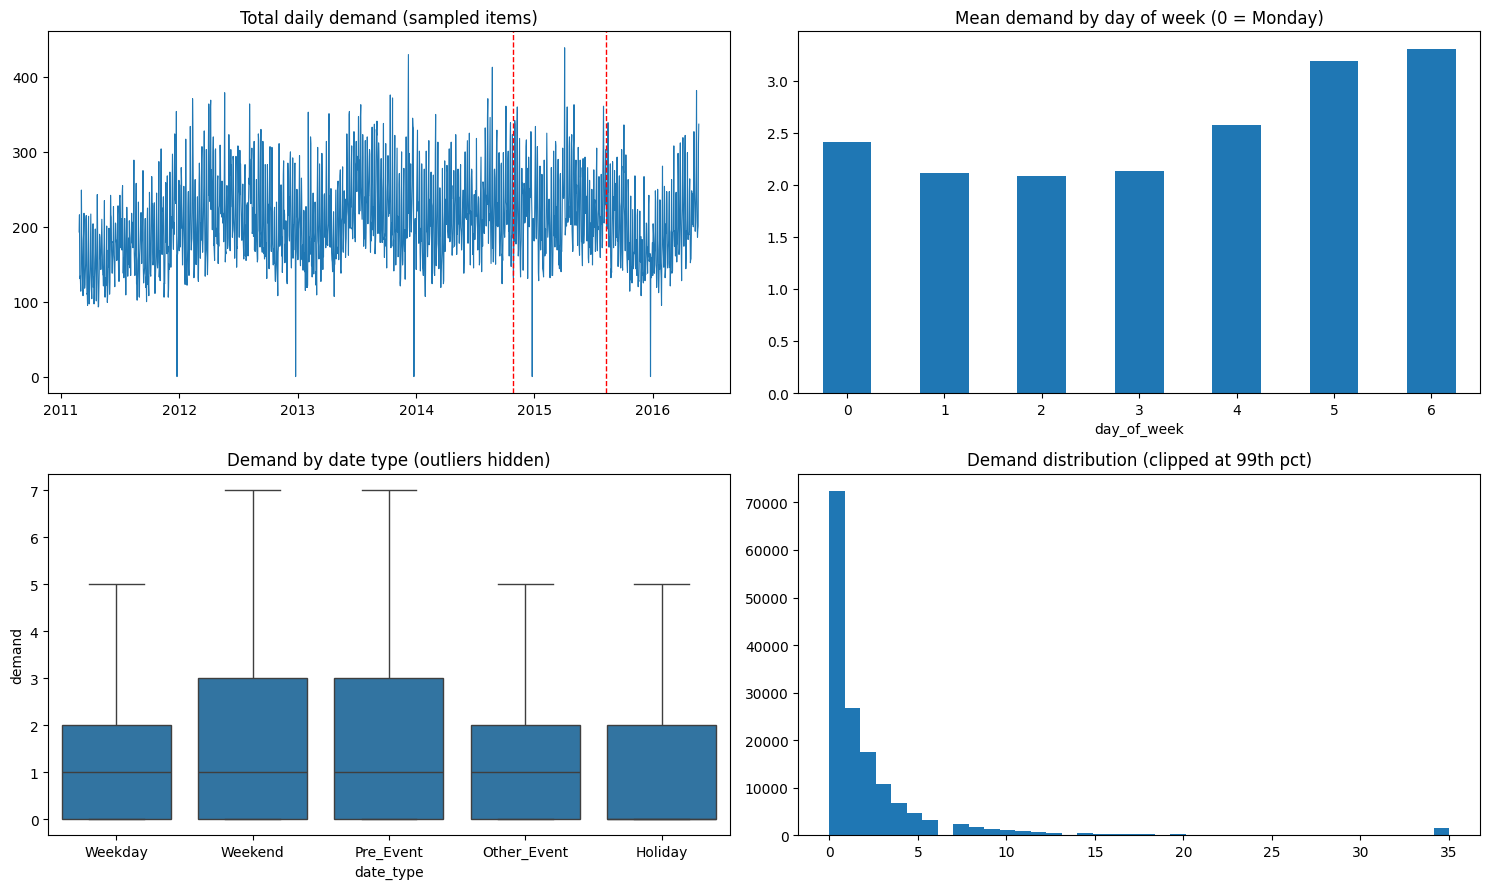

In [12]:
print("=== Dataset summary (for Report §6) ===")
print("Items:", model_df["item_id"].nunique(), "| Rows (model_df):", f"{len(model_df):,}",
      "| Period:", model_df["date"].min().date(), "->", model_df["date"].max().date())
print("Target 'demand' (units/day):"); print(model_df["demand"].describe().round(3).to_string())
print(f"Share of zero-demand days: {100 * (model_df['demand'] == 0).mean():.1f}%")
print("\nDays per date type (calendar, all days):"); print(cal["date_type"].value_counts().to_string())
print("\nMean demand by date type:"); print(model_df.groupby("date_type")["demand"].mean().round(3).to_string())
print("\nMean demand on SNAP vs non-SNAP days:"); print(model_df.groupby("snap")["demand"].mean().round(3).to_string())

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
daily = model_df.groupby("date")["demand"].sum()
ax[0, 0].plot(daily.index, daily.values, lw=0.8); ax[0, 0].set_title("Total daily demand (sampled items)")
for d in [train_end, val_end]: ax[0, 0].axvline(d, color="red", ls="--", lw=1)
model_df.groupby("day_of_week")["demand"].mean().plot(kind="bar", ax=ax[0, 1], rot=0)
ax[0, 1].set_title("Mean demand by day of week (0 = Monday)")
sns.boxplot(data=model_df, x="date_type", y="demand", order=DATE_TYPES, ax=ax[1, 0], showfliers=False)
ax[1, 0].set_title("Demand by date type (outliers hidden)")
ax[1, 1].hist(model_df["demand"].clip(upper=model_df["demand"].quantile(0.99)), bins=40)
ax[1, 1].set_title("Demand distribution (clipped at 99th pct)")
save_fig("fig_eda.png")

## 7. Feature sets for the ablation
| Set | LightGBM features | LSTM inputs |
|---|---|---|
| **A** – history only | lags, rolling stats, item | 28-day window of log-demand + item embedding |
| **B** – A + calendar/date type | + weekday, month, weekend, holiday, event, pre-event, distance to events, `date_type` | + same calendar variables for the past window **and for the forecast day** (future branch) |
| **C** – B + price/SNAP | + SNAP, price, relative price, price change | + SNAP, relative price, price change (window + forecast day) |

Comparing A→B isolates the contribution of calendar/date-type information; B→C isolates price/SNAP.

In [13]:
HIST_LGB  = ["lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28", "rolling_std_28"]
CAL_LGB   = ["day_of_week", "day_of_month", "week_of_year", "month", "is_weekend", "is_holiday", "has_event",
             "is_pre_event", "days_to_next_event", "days_since_last_event", "date_type_cat"]
PRICE_LGB = ["snap", "sell_price", "price_rel_28", "price_change_7"]
LGB_SETS = {
    "A": HIST_LGB + ["item_cat"],
    "B": HIST_LGB + CAL_LGB + ["item_cat"],
    "C": HIST_LGB + CAL_LGB + PRICE_LGB + ["item_cat"],
}

CAL_LSTM   = ["dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend", "is_holiday", "has_event",
              "is_pre_event", "dts", "dsl"] + [f"dt_{d}" for d in DATE_TYPES]
PRICE_LSTM = ["snap", "price_rel_28", "price_change_7"]
LSTM_SETS = {
    "A": dict(hist=["log_demand"],                              fut=[]),
    "B": dict(hist=["log_demand"] + CAL_LSTM,                   fut=CAL_LSTM),
    "C": dict(hist=["log_demand"] + CAL_LSTM + PRICE_LSTM,      fut=CAL_LSTM + PRICE_LSTM),
}
for k in LGB_SETS: print(f"LightGBM-{k}: {len(LGB_SETS[k])} features")
for k in LSTM_SETS: print(f"LSTM-{k}: hist={len(LSTM_SETS[k]['hist'])} channels, future={len(LSTM_SETS[k]['fut'])} channels")

LightGBM-A: 8 features
LightGBM-B: 19 features
LightGBM-C: 23 features
LSTM-A: hist=1 channels, future=0 channels
LSTM-B: hist=16 channels, future=15 channels
LSTM-C: hist=19 channels, future=18 channels


## 8. Evaluation framework
* **MAE, RMSE** – scale-dependent. **WAPE** = Σ|e| / Σy – easy to interpret, robust to zeros. **RMSSE** – scaled by the naive one-step error on the training set of each item (M5 style). **Bias** = mean(ŷ − y): >0 over-forecast (excess stock), <0 under-forecast (stock-outs).
* sMAPE is kept **only as an auxiliary metric**: with many zero-demand days it explodes (y = 0, ŷ > 0 → 200%).
* All forecasts are clipped at 0 and evaluated on the **same rows** of `test_eval`.

In [14]:
def wape(y, p):  return float(np.abs(y - p).sum() / (np.abs(y).sum() + 1e-8))
def bias(y, p):  return float(np.mean(p - y))

def metrics_row(df, col):
    y, p = df["demand"].to_numpy(float), df[col].to_numpy(float)
    return {"MAE": np.mean(np.abs(y - p)),
            "RMSE": np.sqrt(np.mean((y - p) ** 2)),
            "WAPE_%": 100 * wape(y, p),
            "RMSSE": np.sqrt(np.mean((y - p) ** 2 / df["scale"].to_numpy(float))),
            "Bias": bias(y, p),
            "sMAPE_%(aux)": 100 * np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p) + 1e-8))}

def metrics_table(df, cols):
    return pd.DataFrame({c: metrics_row(df, c) for c in cols}).T.round(4)

# evaluation frame: one row per (item_id, date) of the test period
test_eval = test[["item_id", "date", "demand", "date_type", "snap", "vol_bin"]].copy().reset_index(drop=True)
train_scale = train.groupby("item_id")["demand"].apply(lambda s: float(np.mean(np.diff(s.to_numpy()) ** 2)))
fallback = train_scale[train_scale > 0].median()
test_eval["scale"] = test_eval["item_id"].map(train_scale).replace(0, fallback).fillna(fallback)

# val frame (only used to select LightGBM hyper-parameters)
val_eval = val[["item_id", "date", "demand"]].copy().reset_index(drop=True)
print("Test rows:", len(test_eval), "| Test days:", test_eval["date"].nunique())

Test rows: 28700 | Test days: 287


## 9. Baselines
Naive (yesterday), Seasonal Naive (same weekday last week), Moving Average of the last 28 days.

In [15]:
test_eval["Naive"]          = test["lag_1"].to_numpy()
test_eval["Seasonal Naive"] = test["lag_7"].to_numpy()
test_eval["MA28"]           = test["rolling_mean_28"].to_numpy()
print(metrics_table(test_eval, ["Naive", "Seasonal Naive", "MA28"]))

                   MAE    RMSE   WAPE_%   RMSSE    Bias  sMAPE_%(aux)
Naive           1.4456  2.9468  74.1171  1.0256 -0.0012       78.2650
Seasonal Naive  1.4838  2.8878  76.0750  1.0324  0.0038       82.8045
MA28            1.2658  2.4793  64.8984  0.7859 -0.0012      105.6971


## 10. LightGBM (machine-learning baseline)
* Objective **Tweedie** (non-negative, zero-inflated count data – common in M5 solutions) instead of plain L2.
* `subsample_freq=1` added (in the old notebook `subsample=0.8` had no effect without it).
* `year` removed from features (a tree cannot extrapolate to unseen years).
* Small grid over tree complexity, selected by **validation WAPE**; early stopping on validation.

set  num_leaves  min_child_samples  best_iter  val_WAPE_%
  A          15                 50        164      57.260
  A          31                 20        146      57.183
  A          63                 20        129      57.155
  B          15                 50        529      55.044
  B          31                 20        379      54.836
  B          63                 20        179      55.079
  C          15                 50        723      55.029
  C          31                 20        348      54.771
  C          63                 20        168      55.046

LightGBM training time (seconds):
set  num_leaves  min_child_samples  fit_sec  best_iter  selected  predict_sec
  A          15                 50     3.00        164     False          NaN
  A          31                 20     2.97        146     False          NaN
  A          63                 20     3.15        129      True         0.23
  B          15                 50     8.27        529     False         

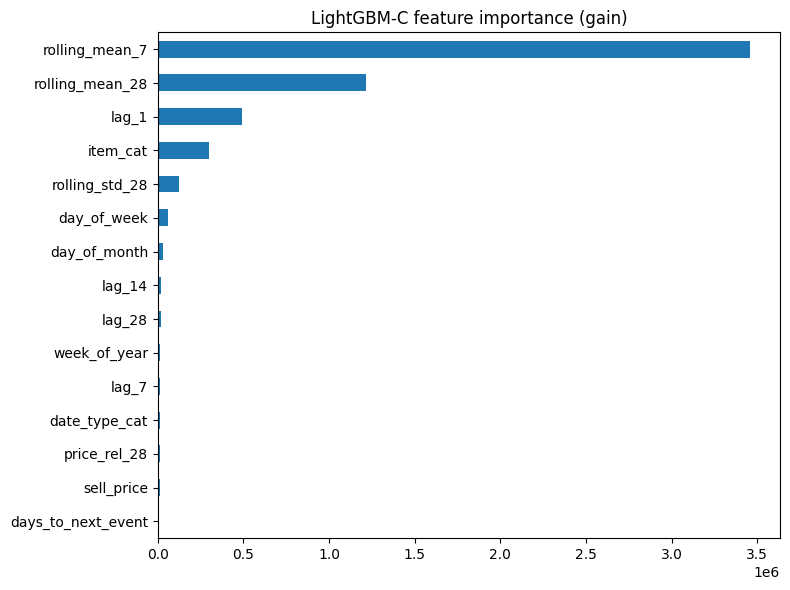

In [16]:
import lightgbm as lgb

LGB_GRID = [dict(num_leaves=15, min_child_samples=50),
            dict(num_leaves=31, min_child_samples=20),
            dict(num_leaves=63, min_child_samples=20)]

lgb_models, lgb_best_params, lgb_val_log = {}, {}, []
lgb_time_log = []          # one row per fit: set, config, fit_sec, best_iter
for fs, cols in LGB_SETS.items():
    best = None
    for params in LGB_GRID:
        m = lgb.LGBMRegressor(objective="tweedie", tweedie_variance_power=1.2, n_estimators=3000,
                              learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=SEED, verbose=-1, **params)
        with StopWatch() as sw:                                   # wall-clock training time of this fit
            m.fit(train[cols], train["demand"], eval_set=[(val[cols], val["demand"])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        lgb_time_log.append({"set": fs, **params, "fit_sec": sw.seconds, "best_iter": m.best_iteration_})
        v = wape(val["demand"].to_numpy(), np.clip(m.predict(val[cols]), 0, None))
        lgb_val_log.append({"set": fs, **params, "best_iter": m.best_iteration_, "val_WAPE_%": round(100 * v, 3)})
        if best is None or v < best[0]:
            best = (v, m, params)
    lgb_models[fs], lgb_best_params[fs] = best[1], best[2]
    with StopWatch() as sw_pred:
        test_eval[f"LightGBM-{fs}"] = np.clip(best[1].predict(test[cols]), 0, None)
    for r in lgb_time_log:
        if r["set"] == fs:
            r["selected"] = all(r[k] == v for k, v in best[2].items())
            r["predict_sec"] = sw_pred.seconds if r["selected"] else np.nan

print(pd.DataFrame(lgb_val_log).to_string(index=False))
lgb_time_log = pd.DataFrame(lgb_time_log)
print("\nLightGBM training time (seconds):")
print(lgb_time_log.round(2).to_string(index=False))
print(metrics_table(test_eval, [f"LightGBM-{k}" for k in LGB_SETS]))

# feature importance (gain) for the full model C
imp = pd.Series(lgb_models["C"].booster_.feature_importance("gain"), index=LGB_SETS["C"]).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), title="LightGBM-C feature importance (gain)")
save_fig("fig_lgb_importance.png")

## 11. LSTM (primary deep-learning model)
**Architecture (two-branch):**
* *History branch*: stacked LSTM encodes the last 28 days (log-demand [+ calendar, + price]).
* *Future branch*: the **known calendar / date type / SNAP / price of the forecast day** are concatenated with the LSTM state (this was missing in the old notebook, so the LSTM could not really be "calendar-aware").
* *Item embedding*: gives the LSTM the same item-identity information that LightGBM has.
* Output `softplus` + **Poisson loss** → non-negative expected demand, consistent with the Tweedie LightGBM. Inputs are standardised with statistics from the training period only.
* Sequences are built per item (no window crosses two items); a window belongs to train/val/test according to its **target date(s)**.

In [26]:
# ---- standardise continuous inputs with TRAIN statistics only ----
SCALE_COLS = ["log_demand", "price_rel_28", "price_change_7"]
lstm_df = sales_long.copy()
tr_rows = lstm_df["split"] == "train"
mu, sd = lstm_df.loc[tr_rows, SCALE_COLS].mean(), lstm_df.loc[tr_rows, SCALE_COLS].std().replace(0, 1)
lstm_df[SCALE_COLS] = (lstm_df[SCALE_COLS] - mu) / sd

def build_sequences(df, hist_cols, fut_cols, lookback, horizon):
    """Vectorised, per-item sliding windows.
    Xh: (N, lookback, n_hist)  past window   | Xf: (N, horizon, n_fut) calendar etc. of the forecast days
    Y : (N, horizon) raw demand of the forecast days | start/end: first/last forecast date of each window"""
    out = {k: [] for k in ["Xh", "Xf", "item", "Y", "start", "end", "item_id"]}
    for item_id, g in df.groupby("item_id", sort=False):
        g = g.sort_values("date")
        n = len(g); m = n - lookback - horizon + 1
        if m <= 0:
            continue
        H_arr = g[hist_cols].to_numpy(np.float32)
        out["Xh"].append(sliding_window_view(H_arr, lookback, axis=0)[:m].transpose(0, 2, 1))
        y = g["demand"].to_numpy(np.float32)
        out["Y"].append(sliding_window_view(y, horizon)[lookback:lookback + m])
        if fut_cols:
            F_arr = g[fut_cols].to_numpy(np.float32)
            out["Xf"].append(sliding_window_view(F_arr, horizon, axis=0)[lookback:lookback + m].transpose(0, 2, 1))
        dts = pd.to_datetime(g["date"]).astype("datetime64[ns]").to_numpy()
        out["start"].append(dts[lookback:lookback + m])
        out["end"].append(dts[lookback + horizon - 1: lookback + horizon - 1 + m])
        out["item"].append(np.full(m, g["item_code"].iloc[0], dtype=np.int32))
        out["item_id"].append(np.full(m, item_id, dtype=object))
    seq = {k: (np.concatenate(v) if len(v) else None) for k, v in out.items()}
    seq["item"] = seq["item"].reshape(-1, 1)
    return seq

def split_masks(seq, t_end, v_end):
    t_end, v_end = np.datetime64(t_end), np.datetime64(v_end)
    tr = seq["end"] <= t_end                                     # whole target window inside train
    va = (seq["start"] > t_end) & (seq["end"] <= v_end)          # inside validation
    te = seq["start"] > v_end                                    # forecast origin in test
    return tr, va, te

def make_inputs(seq, mask):
    d = {"hist": seq["Xh"][mask], "item": seq["item"][mask]}
    if seq["Xf"] is not None:
        d["future"] = seq["Xf"][mask]
    return d

def attach_preds(base, seq, mask, pred_1d, col):
    # Explicitly cast types to eliminate alignment issues
    seq_dates = pd.to_datetime(seq["end"][mask]).astype("datetime64[ns]")
    tmp = pd.DataFrame({"item_id": seq["item_id"][mask],
                        "date": seq_dates,
                        col: np.asarray(pred_1d, dtype=float)})

    base_df = base.copy()
    base_df["date"] = pd.to_datetime(base_df["date"]).astype("datetime64[ns]")

    # Clear any old columns with the same name to prevent duplicates
    if col in base_df.columns:
        base_df = base_df.drop(columns=[col])

    out = base_df.merge(tmp, on=["item_id", "date"], how="left")
    return out

In [27]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
HW = hardware_info(tf.config.list_physical_devices("GPU")); print("Hardware:", HW)

def build_lstm(n_hist, n_fut, n_items, horizon=1, lookback=LOOKBACK):
    hist_in = layers.Input((lookback, n_hist), name="hist")
    item_in = layers.Input((1,), dtype="int32", name="item")
    emb = layers.Flatten()(layers.Embedding(n_items, 4)(item_in))
    h = layers.LSTM(LSTM_UNITS[0], return_sequences=True)(hist_in)
    h = layers.Dropout(DROPOUT)(h)
    h = layers.LSTM(LSTM_UNITS[1])(h)
    h = layers.Dropout(DROPOUT)(h)
    parts, inputs = [h, emb], [hist_in, item_in]
    if n_fut > 0:                                              # future-known covariates of the forecast day(s)
        fut_in = layers.Input((horizon, n_fut), name="future")
        parts.append(layers.Flatten()(fut_in)); inputs.append(fut_in)
    z = layers.Dense(32, activation="relu")(layers.Concatenate()(parts))
    out = layers.Dense(horizon, activation="softplus")(z)      # non-negative expected demand
    model = Model(inputs, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=LSTM_LOSS)
    return model

def make_callbacks():
    return [EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]

lstm_histories, lstm_run_log = {}, []
for fs, spec in LSTM_SETS.items():
    seq = build_sequences(lstm_df, spec["hist"], spec["fut"], LOOKBACK, HORIZON)
    tr, va, te = split_masks(seq, train_end, val_end)
    assert te.sum() == len(test_eval), f"Test windows ({te.sum()}) != test rows ({len(test_eval)})"
    print(f"\n=== LSTM-{fs}: train {tr.sum():,} | val {va.sum():,} | test {te.sum():,} windows ===")
    for seed in SEEDS:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        model = build_lstm(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), HORIZON)
        t0 = time.perf_counter()
        hist = model.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                         epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)
        fit_sec = time.perf_counter() - t0
        with StopWatch() as sw_pred:
            pred = np.clip(model.predict(make_inputs(seq, te), batch_size=2048, verbose=0)[:, 0], 0, None)
        test_eval = attach_preds(test_eval, seq, te, pred, f"LSTM-{fs}_s{seed}")
        lstm_histories[(fs, seed)] = hist.history
        lstm_run_log.append({"set": fs, "seed": seed, "epochs": len(hist.history["loss"]),
                             "best_val_loss": round(min(hist.history["val_loss"]), 5), "sec": round(fit_sec, 1),
                             "sec_per_epoch": round(fit_sec / len(hist.history["loss"]), 2),
                             "predict_sec": round(sw_pred.seconds, 2),
                             "params": int(model.count_params())})
        print(lstm_run_log[-1])
    test_eval[f"LSTM-{fs}"] = test_eval[[f"LSTM-{fs}_s{s}" for s in SEEDS]].mean(axis=1)   # seed ensemble
    del seq; gc.collect()
lstm_run_log = pd.DataFrame(lstm_run_log)
print("\nLSTM training time:"); print(lstm_run_log.to_string(index=False))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Hardware: {'python': '3.13.16', 'machine': 'x86_64', 'processor': 'x86_64', 'cpu_count': 2, 'gpu': "PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"}

=== LSTM-A: train 99,319 | val 28,267 | test 28,700 windows ===
{'set': 'A', 'seed': 42, 'epochs': 40, 'best_val_loss': -1.94584, 'sec': 166.5, 'sec_per_epoch': 4.16, 'predict_sec': 0.49, 'params': 30929}
{'set': 'A', 'seed': 7, 'epochs': 32, 'best_val_loss': -1.94521, 'sec': 130.7, 'sec_per_epoch': 4.08, 'predict_sec': 0.57, 'params': 30929}
{'set': 'A', 'seed': 2024, 'epochs': 40, 'best_val_loss': -1.9474, 'sec': 166.4, 'sec_per_epoch': 4.16, 'predict_sec': 0.52, 'params': 30929}

=== LSTM-B: train 99,319 | val 28,267 | test 28,700 windows ===
{'set': 'B', 'seed': 42, 'epochs': 35, 'best_val_loss': -1.95788, 'sec': 156.2, 'sec_per_epoch': 4.46, 'predict_sec': 1.52, 'params': 35249}
{'set': 'B', 'seed': 7, 'epochs': 23, 'best_val

## 12. Results (Report: Results and Discussion)
### 12.1 Main comparison – same test rows for every model

In [28]:
MODEL_ORDER = ["Naive", "Seasonal Naive", "MA28"] + [f"LightGBM-{k}" for k in "ABC"] + [f"LSTM-{k}" for k in "ABC"]
MODEL_ORDER = [m for m in MODEL_ORDER if m in test_eval.columns]
results = metrics_table(test_eval, MODEL_ORDER)
print("Test set:", len(test_eval), "rows |", test_eval["date"].min().date(), "->", test_eval["date"].max().date())
display(results) if "display" in globals() else print(results)

# LSTM seed variability (single-seed metrics, mean ± std)
seed_cols = [c for c in test_eval.columns if c.startswith("LSTM-") and "_s" in c]
if seed_cols:
    rows = []
    for fs in "ABC":
        per_seed = pd.DataFrame({c: metrics_row(test_eval, c) for c in seed_cols if c.startswith(f"LSTM-{fs}_s")}).T
        if len(per_seed):
            rows.append({"set": f"LSTM-{fs}", "n_seeds": len(per_seed),
                         "WAPE_% mean": per_seed["WAPE_%"].mean(), "WAPE_% std": per_seed["WAPE_%"].std(),
                         "RMSE mean": per_seed["RMSE"].mean(), "RMSE std": per_seed["RMSE"].std()})
    print("\nLSTM across seeds:"); print(pd.DataFrame(rows).round(4).to_string(index=False))

Test set: 28700 rows | 2015-08-10 -> 2016-05-22
                   MAE    RMSE   WAPE_%   RMSSE    Bias  sMAPE_%(aux)
Naive           1.4456  2.9468  74.1171  1.0256 -0.0012       78.2650
Seasonal Naive  1.4838  2.8878  76.0750  1.0324  0.0038       82.8045
MA28            1.2658  2.4793  64.8984  0.7859 -0.0012      105.6971
LightGBM-A      1.2031  2.1667  61.6805  0.7613  0.0778      127.0693
LightGBM-B      1.1630  2.0905  59.6283  0.7498  0.0711      127.5557
LightGBM-C      1.1618  2.0909  59.5650  0.7492  0.0687      127.4745
LSTM-A          1.1927  2.1850  61.1502  0.7753  0.0884      128.2878
LSTM-B          1.1834  2.1751  60.6707  0.7686  0.1034      128.1900
LSTM-C          1.1817  2.1620  60.5846  0.7678  0.1089      127.9350

LSTM across seeds:
   set  n_seeds  WAPE_% mean  WAPE_% std  RMSE mean  RMSE std
LSTM-A        3      61.2065      0.2839     2.1902    0.0129
LSTM-B        3      60.7636      0.2428     2.1828    0.0181
LSTM-C        3      60.7545      0.4662     2

### 12.2 Ablation – does calendar / date-type information help? (RQ1)
Size of the change in WAPE and RMSE from set A to B to C. For LSTM, compare the change with the seed-to-seed standard deviation printed in 12.1.


In [29]:
abl = []
for fam in ["LightGBM", "LSTM"]:
    if f"{fam}-A" not in results.index: continue
    base = results.loc[f"{fam}-A"]
    for fs in "ABC":
        r = results.loc[f"{fam}-{fs}"]
        abl.append({"model": fam, "feature set": fs,
                    "WAPE_%": r["WAPE_%"], "RMSE": r["RMSE"],
                    "WAPE change vs A (%)": 100 * (r["WAPE_%"] / base["WAPE_%"] - 1),
                    "RMSE change vs A (%)": 100 * (r["RMSE"] / base["RMSE"] - 1)})
abl = pd.DataFrame(abl).round(3)
print(abl.to_string(index=False))


   model feature set  WAPE_%  RMSE  WAPE change vs A (%)  RMSE change vs A (%)
LightGBM           A  61.680 2.167                 0.000                 0.000
LightGBM           B  59.628 2.090                -3.327                -3.517
LightGBM           C  59.565 2.091                -3.430                -3.498
    LSTM           A  61.150 2.185                 0.000                 0.000
    LSTM           B  60.671 2.175                -0.784                -0.453
    LSTM           C  60.585 2.162                -0.925                -1.053


### 12.3 Error analysis by date type (RQ3) – the core of the "calendar-aware" claim

WAPE (%) by date type
             test_days  Seasonal Naive  LightGBM-A  LightGBM-C  LSTM-A  LSTM-C
date_type                                                                     
Weekday            160           80.00       65.76       62.67   65.31   63.35
Weekend             63           68.23       53.41       53.39   53.11   54.92
Pre_Event           41           76.25       61.61       60.26   59.87   60.45
Other_Event          7           77.29       60.20       57.96   59.45   59.81
Holiday             16           80.96       69.72       63.03   70.78   66.58

Bias by date type (>0 over-forecast, <0 under-forecast)
             Seasonal Naive  LightGBM-A  LightGBM-C  LSTM-A  LSTM-C
date_type                                                          
Weekday               0.037       0.244       0.091   0.213   0.104
Weekend              -0.041      -0.334       0.027  -0.226   0.102
Pre_Event            -0.051       0.022       0.084   0.025   0.133
Other_Event           0.036 

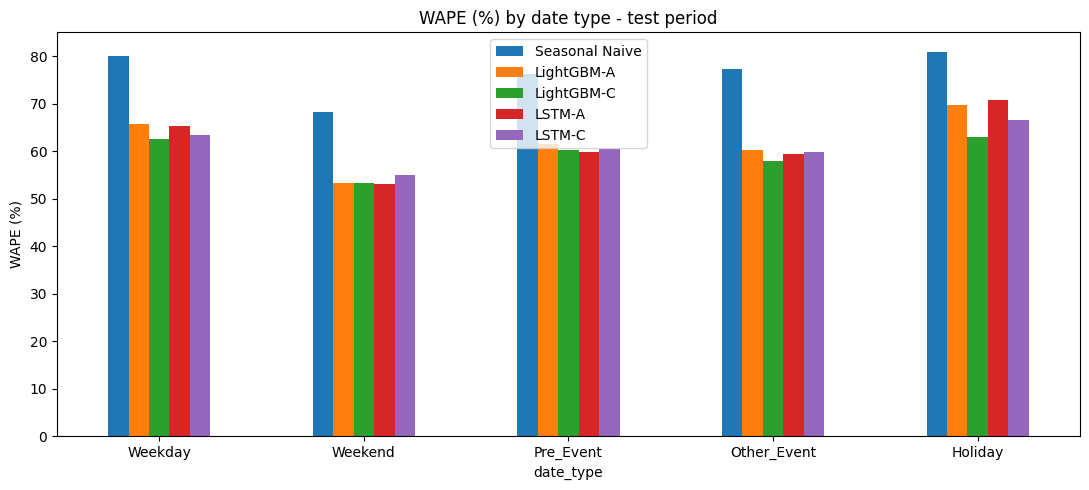

In [30]:
cmp_models = [m for m in ["Seasonal Naive", "LightGBM-A", "LightGBM-C", "LSTM-A", "LSTM-C"] if m in test_eval.columns]

def grouped_metric(df, by, cols, fn):
    return pd.DataFrame({c: df.groupby(by).apply(lambda x: fn(x["demand"].to_numpy(float), x[c].to_numpy(float))) for c in cols})

wape_dt = (100 * grouped_metric(test_eval, "date_type", cmp_models, wape)).reindex(DATE_TYPES).round(2)
bias_dt = grouped_metric(test_eval, "date_type", cmp_models, bias).reindex(DATE_TYPES).round(3)
n_dt = test_eval.groupby("date_type")["date"].nunique().reindex(DATE_TYPES).rename("test_days")
print("WAPE (%) by date type"); print(pd.concat([n_dt, wape_dt], axis=1).to_string())
print("\nBias by date type (>0 over-forecast, <0 under-forecast)"); print(bias_dt.to_string())

wape_snap = (100 * grouped_metric(test_eval, "snap", cmp_models, wape)).round(2); wape_snap.index = ["non-SNAP", "SNAP"][:len(wape_snap)]
wape_vol = (100 * grouped_metric(test_eval, "vol_bin", cmp_models, wape)).round(2); wape_vol.index = [f"volume quintile {i+1}" for i in wape_vol.index]
print("\nWAPE (%) by SNAP day"); print(wape_snap.to_string())
print("\nWAPE (%) by item volume quintile (1 = slowest, 5 = fastest)"); print(wape_vol.to_string())

wape_dt.plot(kind="bar", figsize=(11, 5), rot=0, title="WAPE (%) by date type - test period"); plt.ylabel("WAPE (%)")
save_fig("fig_wape_by_date_type.png")

### 12.4 Forecast plots and training curves

Best model on test by WAPE: LightGBM-C


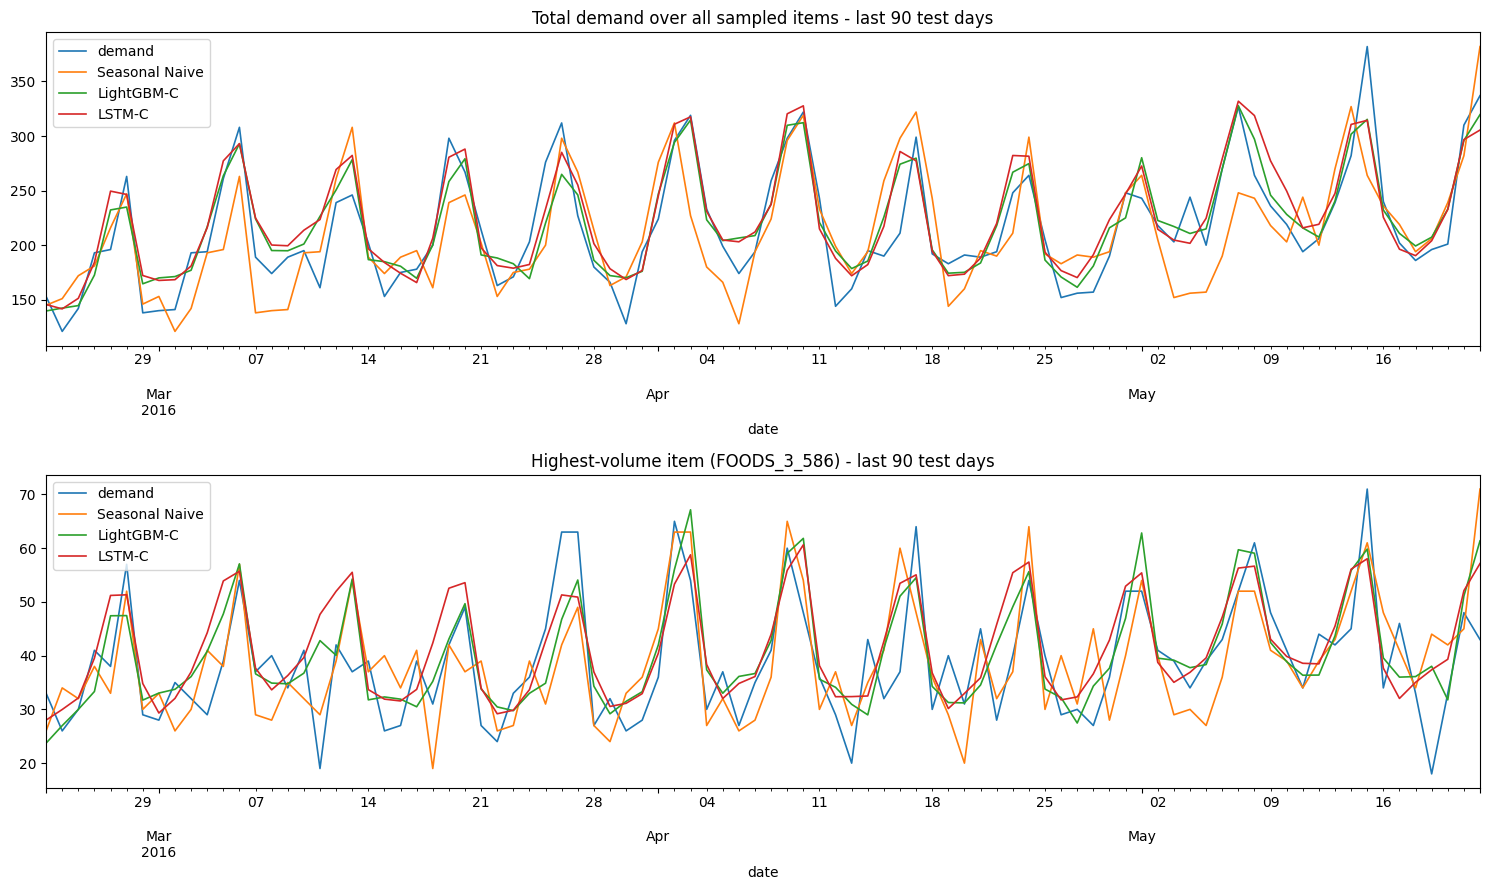

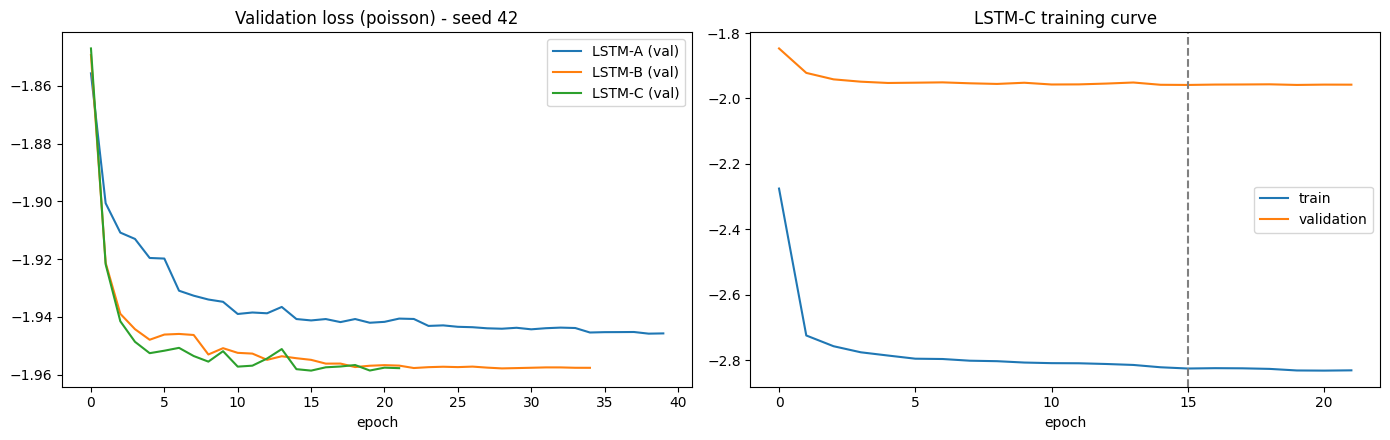

In [31]:
best_name = results.loc[[m for m in results.index if m.startswith(("LightGBM", "LSTM"))], "WAPE_%"].idxmin()
print("Best model on test by WAPE:", best_name)

fig, ax = plt.subplots(2, 1, figsize=(15, 9))
agg_cols = ["demand"] + [m for m in ["Seasonal Naive", "LightGBM-C", "LSTM-C"] if m in test_eval.columns]
agg = test_eval.groupby("date")[agg_cols].sum()
agg.tail(90).plot(ax=ax[0], lw=1.2); ax[0].set_title("Total demand over all sampled items - last 90 test days")
top_item = test_eval.groupby("item_id")["demand"].sum().idxmax()
one = test_eval[test_eval["item_id"] == top_item].set_index("date")[agg_cols].tail(90)
one.plot(ax=ax[1], lw=1.2); ax[1].set_title(f"Highest-volume item ({top_item}) - last 90 test days")
save_fig("fig_actual_vs_pred.png")

if lstm_histories:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for fs in "ABC":
        if (fs, SEEDS[0]) in lstm_histories:
            ax[0].plot(lstm_histories[(fs, SEEDS[0])]["val_loss"], label=f"LSTM-{fs} (val)")
    ax[0].set_title(f"Validation loss ({LSTM_LOSS}) - seed {SEEDS[0]}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    h = lstm_histories[("C", SEEDS[0])]
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
    ax[1].axvline(int(np.argmin(h["val_loss"])), ls="--", color="gray")
    ax[1].set_title("LSTM-C training curve"); ax[1].set_xlabel("epoch"); ax[1].legend()
    save_fig("fig_lstm_curves.png")

### 12.5 Training time and accuracy (RQ4)
Wall-clock training time of every fit, next to test accuracy. **total_train_sec** = all fits of one feature set (LightGBM: 3 configurations of the small grid; LSTM: 3 seeds), **final_model_sec** = the model that produces the forecast (LightGBM: selected configuration; LSTM: mean of one seed). Both models run on the same runtime.

Reading guide: the purpose is **not** to say which model is faster, but to check whether more training time buys more accuracy. In v2 (CPU runtime) LSTM-A was more accurate than LightGBM-A by WAPE although each LSTM run took 661–1,577 s.


Hardware: {'python': '3.13.16', 'machine': 'x86_64', 'processor': 'x86_64', 'cpu_count': 2, 'gpu': "PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"}
   model set  fits  total_train_sec  sec_per_fit  final_model_sec      units  WAPE_%   MAE  RMSE
LightGBM   A     3            9.121        3.040            3.147    129 cây  61.680 1.203 2.167
LightGBM   B     3           20.142        6.714            7.316    379 cây  59.628 1.163 2.090
LightGBM   C     3           23.420        7.807            7.157    348 cây  59.565 1.162 2.091
    LSTM   A     3          463.600      154.533          154.533 37.3 epoch  61.150 1.193 2.185
    LSTM   B     3          380.100      126.700          126.700 29.0 epoch  60.671 1.183 2.175
    LSTM   C     3          316.600      105.533          105.533 24.7 epoch  60.585 1.182 2.162

LSTM / LightGBM time ratio:
     LSTM / LightGBM (total_train_sec)  LSTM / LightGBM (final_model_sec)
set                                                

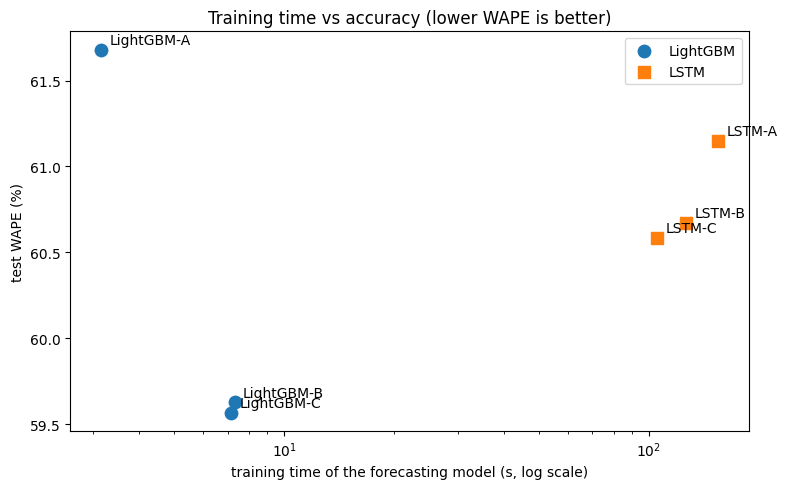

In [32]:
time_summary = summarise_training_time(lgb_time_log, lstm_run_log, results)
print("Hardware:", HW if "HW" in globals() else hardware_info())
display(time_summary.round(3)) if "display" in globals() else print(time_summary.round(3).to_string(index=False))
print("\nLSTM / LightGBM time ratio:"); print(pd.concat([time_ratio(time_summary, "total_train_sec"),
                                                       time_ratio(time_summary, "final_model_sec")], axis=1).round(1))

fig, ax = plt.subplots(figsize=(8, 5))
for fam, mk in [("LightGBM", "o"), ("LSTM", "s")]:
    d = time_summary[time_summary["model"] == fam]
    ax.scatter(d["final_model_sec"], d["WAPE_%"], marker=mk, s=80, label=fam)
    for _, r in d.iterrows():
        ax.annotate(f"{fam}-{r['set']}", (r["final_model_sec"], r["WAPE_%"]), textcoords="offset points", xytext=(6, 4))
ax.set_xscale("log"); ax.set_xlabel("training time of the forecasting model (s, log scale)"); ax.set_ylabel("test WAPE (%)")
ax.set_title("Training time vs accuracy (lower WAPE is better)"); ax.legend()
save_fig("fig_time_vs_wape.png")


## 13. Save outputs

In [33]:
results.to_csv(os.path.join(OUT_DIR, "results_main.csv"))
abl.to_csv(os.path.join(OUT_DIR, "results_ablation.csv"), index=False)
lgb_time_log.to_csv(os.path.join(OUT_DIR, "training_time_lightgbm.csv"), index=False)
lstm_run_log.to_csv(os.path.join(OUT_DIR, "training_time_lstm.csv"), index=False)
time_summary.to_csv(os.path.join(OUT_DIR, "training_time_summary.csv"), index=False)
wape_dt.to_csv(os.path.join(OUT_DIR, "results_wape_by_date_type.csv"))
test_eval.to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)
print("Saved to", OUT_DIR)

Saved to /root/.cache/kagglehub/datasets/aryayadav0513/m5-forecasting-accuracy/versions/1/outputs
